In [1]:
import matplotlib, matplotlib.pyplot as plt
import stpsf
from astropy.io import fits
import numpy as np
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from matplotlib.colors import LogNorm
import random
import astropy
import oplanet

/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def radial_profil(image,dim,lam,ndr):
    x0=dim/2
    y0=dim/2
    Y, X = np.ogrid[:dim, :dim]
    dr = ndr*lam/6.5*180.*3600./np.pi/0.11/4. #pour faire une zone de 1,5*2 = 3 L/D de diametre

    mask_pla   = np.sqrt((X - x0 + 0.5)**2 + (Y - y0 + 0.5)**2)

    ### Std dev azimutale dans un anneau de 3 L/D de largeur
    std      = np.ndarray(dim//2)#self.dim//2)
    for scan in range(0,dim//2): #self.dim//2):
        mask_sel = (mask_pla >= scan-dr) * (mask_pla < scan+dr)
        std[scan]   = np.nanstd(image[mask_sel])  ### radial 
    return std

def add_photon_noise(obs, flux_star=70e-3, filtername="F1140C"):

    flux_Jy = obs * flux_star
    sfilter = oplanet.SFilter(filtername)
    n_photons = sfilter.get_nphotons(flux_Jy, A=26, exposure_time=3600)
    rel_sigma = 1/np.sqrt(n_photons)
    obs_sigma = obs * rel_sigma ## why "obs" ???

    obs_noise = np.random.normal(loc=flux_Jy, scale=obs_sigma)
    return obs_noise

In [3]:
### pour créer une grille de reference avec 1mas d'écart de -10 a 10 mas
if False:
    for i in range(-10,11,1):
        for j in range(-10,11,1):
            miri = stpsf.MIRI()
            miri.filter = 'F1140C'
            miri.image_mask = 'FQPM1140' #'LYOT2300'
            miri.pupil_mask = 'MASKFQPM' #'MASKLYOT'
            miri.options['source_offset_x'] = i*0.001      # offset is in arcsec
            miri.options['source_offset_y'] = j*0.001      # offset is in arcsec
            coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=200,oversample=4)

            coron_psf.writeto('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/F1140C_sgd_offset_x='+str(i)+'_y='+str(j)+'.fits', overwrite=True)
    stpsf.display_psf(coron_psf,vmin=1e-9,vmax=1e-5) 

In [21]:
### observation science
miri = stpsf.MIRI()
miri.filter = 'F1140C'
miri.image_mask = 'FQPM1140' #'LYOT2300'
miri.pupil_mask = 'MASKFQPM' #'MASKLYOT'
miri.options['source_offset_x'] = 0      # offset is in arcsec
miri.options['source_offset_y'] = 0      # offset is in arcsec
coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=200,oversample=4)

#coron_psf.writeto('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/F1140C_observation.fits', overwrite=True)

In [30]:
obs = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/F1140C_observation.fits')[0].data  

for i in range(-10,11,1):
    fig1 = plt.figure(figsize=(10,7))
    for j in range(-10,11,1):
        ref = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/F1140C_sgd_offset_x='+str(i)+'_y='+str(j)+'.fits')[0].data 
        diff = obs-ref
        std_prof = radial_profil(diff,800,11.4e-6,1.)

        plt.plot(np.arange(0,400,1)*0.11/4.,std_prof,label=str(i)+' / '+str(j))
        if False:
            imp.save_fits(diff,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/diff/F1140C_diff_offset_x='+str(i)+'_y='+str(j)+'.fits')
    plt.yscale('log')
    plt.ylim([1e-11,1e-6])
    plt.xlim([0,11])
    plt.legend(fontsize=14)
    fig1.savefig('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/diff/F1140C_diff_offset_x='+str(i)+'.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)

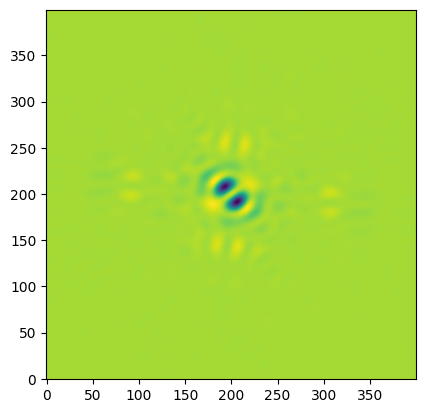

In [53]:
sgd_ref = np.array([[-1,0,1,-1,1,-1,0,1],[1,0,-1,1,-1,1,0,-1]])

offset = 1
trunc = 2

ref = np.ndarray([8,800,800])
obs = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/F1140C_observation.fits')[0].data  

for i in range(8):
    ref[i,:,:] = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/F1140C_sgd_offset_x='+str(offset * sgd_ref[0][i])+'_y='+str(offset * sgd_ref[1][i])+'.fits')[0].data

pca = imp.sub_PCA(obs, ref, [400,400], trunc, dim=200, plot=False)

plt.imshow(pca,origin='lower',interpolation=None)
plt.show()

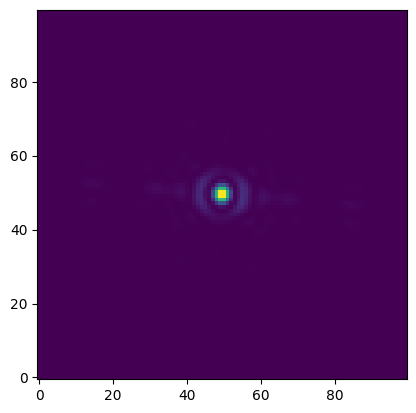

0.5697208128445197
0.5697208128445197
0.01885468022301562
30.216413437183107


In [5]:
## off axis PSF for contrast

obs = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits')[1].data
psf = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/psf_F1140C.fits')[0].data 




if False :
    miri = stpsf.MIRI()
    miri.filter = 'F1140C'
    miri.detector = 'MIRIM'
    miri.aperturename = 'MIRIM_CORON1140'
    miri._detector_position = (109,108)
    #miri.image_mask = 'FQPM1140' #'FQPM1140'
    miri.pupil_mask = 'MASKFQPM' #'MASKFQPM'
    miri.load_wss_opd_by_date('2026-05-16T00:00:00')
    miri.options['source_offset_x'] = 0*35*0.11
    miri.options['source_offset_y'] = 0*35*0.11
    coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=100,oversample=4)
    coron_psf.writeto('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits', overwrite=True)
    psf = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits')[1].data 
    imp.save_fits(psf,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/psf_F1140C.fits')

plt.imshow(psf,origin="lower",interpolation=None)
plt.show()

print(np.sum(obs))
print(np.sum(psf))
print(np.max(psf))
print(np.sum(obs/np.max(psf)))

In [14]:
miri = stpsf.MIRI()
miri.filter = 'F1140C'
miri.detector = 'MIRIM'
#miri.aperturename = 'MIRIM_CORON1140'
miri._detector_position = (109,108)
#miri.image_mask = 'FQPM1140' #'FQPM1140'
#miri.pupil_mask = 'MASKFQPM' #'MASKFQPM'
#miri.load_wss_opd_by_date('2026-05-16T00:00:00')
coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=100,oversample=4)
coron_psf.writeto('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits', overwrite=True)
psf = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits')[1].data

print(np.sum(psf))

0.5677378447692797


In [ ]:


# miri = stpsf.setup_sim_to_match_file('/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs002/P03662_002_TWA7_dither1_cal.fits')
miri = stpsf.MIRI()
miri.filter = 'F1140C'
miri.detector = 'MIRIM'
miri.aperturename = 'MIRIM_CORON1140'
miri._detector_position = (109,108)
miri.image_mask = 'FQPM1140' #'FQPM1140'
miri.pupil_mask = 'MASKFQPM' #'MASKFQPM'
miri.load_wss_opd_by_date('2026-05-19T00:00:00')

# miri = stpsf.setup_sim_to_match_file('/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs004/P03662_004_REF_CD23_9765_dither'+str(ind)+'_cal.fits',choice='before')
miri = stpsf.MIRI()
miri.filter = 'F1140C'
miri.detector = 'MIRIM'
miri.aperturename = 'MIRIM_CORON1140'
miri._detector_position = (109,108)
miri.image_mask = 'FQPM1140' #'FQPM1140'
miri.pupil_mask = 'MASKFQPM' #'MASKFQPM'
miri.load_wss_opd_by_date('2026-05-16T00:00:00') #'2026-05-19T00:00:00')

for pp in [0., 1., 2., 3.]:#[0., 1., 2., 3.]:
    TAe = pp #target acquisition error in mas for the OBS

    ### observation science
    xoffset = TAe*np.sqrt(2.) #random.uniform(-1.,1.)*TAe                                # offset is in arcsec in x axis
    yoffset = TAe*np.sqrt(2.) #np.sqrt(TAe**2 - xoffset**2)*random.choice([-1.,1.])      # offset is in arcsec in y axis
    print("Obs offset : ",xoffset,yoffset)
    miri.options['source_offset_x'] = xoffset*0.001
    miri.options['source_offset_y'] = yoffset*0.001

    coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=100,oversample=4)
    coron_psf.writeto('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits', overwrite=True)
    obs = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits')[1].data  
    imp.save_fits(obs,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/OBSERVATION_diff-OPD_TAe-'+str(TAe)+'.fits')
    


for oo in [10., 7., 5., 3.]: #[10., 7., 5., 3.]:
    offset = oo # offset between each dither in mas for the REF
    for ii in [0.]: #[0., 1., 2.]:
        TAer = ii #target acquisition error in mas for the REF

        ### observation reference
        sgd_ref  = np.array([[-1., 0., 1.],[1., 0., -1.]])
        sgd_ref *= offset
        print(sgd_ref)
        ref = [] #np.ndarray([9,200,200])
        ind = 1 #index to load the good dither image for the setup

        

        #plot the star and ref position
        fig = plt.figure(figsize=(8,8))
        for pp in [0., 1., 2., 3.]:
            plt.plot([pp*np.sqrt(2.)],[pp*np.sqrt(2.)],'.',color="red")
        plt.plot([-15,15],[0,0],'--',color='black')
        plt.plot([0,0],[-15,15],'--',color='black')
        plt.xlim([-15,15])
        plt.ylim([-15,15])
        plt.xlabel("x (mas)")
        plt.ylabel("y (mas)")
        plt.title("SGD err : "+str(TAer)+" (mas) SGD offset : "+str(offset)+" (mas)")
        xoffset_plot = []
        yoffset_plot = []
        for i in sgd_ref[0]:
                for j in sgd_ref[1]:
                    xoffset = random.uniform(-1.,1.)*TAer                                # offset is in arcsec in x axis
                    yoffset = np.sqrt(TAer**2 - xoffset**2)*random.choice([-1.,1.])      # offset is in arcsec in y axis
                    #plot the ref position
                    plt.plot([(i + xoffset)],[j + yoffset],'.',color="blue")
                    plt.plot([i],[j],'+',color='black')
                    miri.options['source_offset_x'] = (i + xoffset)*0.001      # offset is in arcsec
                    miri.options['source_offset_y'] = (j + yoffset)*0.001      # offset is in arcsec
                    coron_psf = miri.calc_psf(nlambda=3,add_distortion=False,fov_pixels=100,oversample=4)
                    coron_psf.writeto('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits', overwrite=True)
                    tmp = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/tmp.fits')[1].data
                    ref.append(tmp)
                    

        fig.savefig('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/SGD_star_position_offset-'+str(offset)+'_errSGD-'+str(TAer)+'.pdf',format='pdf',bbox_inches='tight')
        plt.close(fig)
        ref = np.array(ref)
        imp.save_fits(ref,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/REFERENCE_sgd-'+str(offset)+'_TAer-'+str(TAer)+'.fits')


            

iterating query, tdelta=6.0

MAST OPD query around UTC: 2026-05-19T00:00:00.000
                        MJD: 61179.0

OPD immediately preceding the given datetime:
	URI:	 mast:JWST/product/O2026051901-NRCA1_FP6-1.fits
	Date (MJD):	 61178.9261
	Delta time:	 -0.0739 days

OPD immediately following the given datetime:
	URI:	 mast:JWST/product/R2026052202-NRCA1_FP6-1.fits
	Date (MJD):	 61182.3162
	Delta time:	 3.3162 days
User requested choosing OPD time closest in time to 2026-05-19T00:00:00.000, which is O2026051901-NRCA1_FP6-1.fits, delta time -0.074 days
Importing and format-converting OPD from /home/cperrot/Work/raw/JWST/STPSF/stpsf-data/MAST_JWST_WSS_OPDs/O2026051901-NRCA1_FP6-1.fits
Backing out SI WFE and OTE field dependence at the WF sensing field point (NRCA1_FP6)
Sensing inst model using apername NRCA1_FP6
Using sensing field point SI WFE model from file wss_target_phase_fp6.fits

MAST OPD query around UTC: 2026-05-16T00:00:00.000
                        MJD: 61176.0

OPD immedi

Obs offset :  1.4142135623730951 1.4142135623730951


Obs offset :  2.8284271247461903 2.8284271247461903


Obs offset :  4.242640687119286 4.242640687119286


'   \nfor oo in [10., 7., 5., 3.]: #[10., 7., 5., 3.]:\n    offset = oo # offset between each dither in mas for the REF\n    for ii in [0.]: #[0., 1., 2.]:\n        TAer = ii #target acquisition error in mas for the REF\n\n        ### observation reference\n        sgd_ref  = np.array([[-1., 0., 1.],[1., 0., -1.]])\n        sgd_ref *= offset\n        print(sgd_ref)\n        ref = [] #np.ndarray([9,200,200])\n        ind = 1 #index to load the good dither image for the setup\n\n\n\n        #plot the star and ref position\n        fig = plt.figure(figsize=(8,8))\n        for pp in [0., 1., 2., 3.]:\n            plt.plot([pp*np.sqrt(2.)],[pp*np.sqrt(2.)],\'.\',color="red")\n        plt.plot([-15,15],[0,0],\'--\',color=\'black\')\n        plt.plot([0,0],[-15,15],\'--\',color=\'black\')\n        plt.xlim([-15,15])\n        plt.ylim([-15,15])\n        plt.xlabel("x (mas)")\n        plt.ylabel("y (mas)")\n        plt.title("SGD err : "+str(TAer)+" (mas) SGD offset : "+str(offset)+" (mas)")\n 

In [14]:
### post process
psf = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/psf_F1140C.fits')[0].data 
maxpsf = np.max(psf)

sigman = maxpsf/10. ## valeur a adapter

Y, X = np.ogrid[:100, :100]
mask  = np.sqrt((X - 100/2)**2 + (Y-100/2)**2) >= 0

put_gauss_noise = True
put_photon_noise = True
for pp in [0., 1., 2., 3.]:#[0., 1., 2., 3.]:
    for oo in [10., 7., 5., 3.]: #[10., 7., 5., 3.]:
        for ii in [0., 1., 2.]: #[1., 2.]:
            obs = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/OBSERVATION_TAe-'+str(pp)+'.fits')[0].data
            ref = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/REFERENCE_sgd-'+str(oo)+'_TAer-'+str(ii)+'.fits')[0].data
            if put_photon_noise: 
                obs = add_photon_noise(obs, 70e-3, "F1140C")
                for i in range(9):
                    ref[i,:,:] = add_photon_noise(ref[i,:,:], 70e-3, "F1140C")
            if put_gauss_noise: 
                obs = obs + random.gauss(0.,sigman)
                for i in range(9):
                    ref[i,:,:] = ref[i,:,:] + random.gauss(0.,sigman)


            trunc = 7
            pca = imp.sub_PCA(obs, ref, [50,50], trunc, dim=50, plot=False)
            lcomb = imp.MIRI_linear_comb_mask(obs, ref, mask, use_minimize=False)
            RDI    = imp.RDI_classic(obs, ref, f_scale=1)
            RDI_1d = imp.RDI_classic(obs, ref[4], f_scale=1)

            imp.save_fits(pca/maxpsf,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(pp)+'_sgd-'+str(oo)+'_TAer-'+str(ii)+'_PCA.fits')
            imp.save_fits(lcomb/maxpsf,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(pp)+'_sgd-'+str(oo)+'_TAer-'+str(ii)+'_lcomb.fits')
            imp.save_fits(RDI/maxpsf,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(pp)+'_sgd-'+str(oo)+'_TAer-'+str(ii)+'_RDI.fits')
            imp.save_fits(RDI_1d/maxpsf,'/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(pp)+'_sgd-'+str(oo)+'_TAer-'+str(ii)+'_RDI_1d.fits')



In [15]:

for pp in [0., 1., 2., 3.]:
    TAe = pp #target acquisition error in mas for the OBS
    for ii in [0. ,1., 2.]:
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
        TAer = ii #target acquisition error in mas for the REF
        for oo in [10., 7., 5., 3.]:
            offset = oo # offset between each dither in mas for the REF
        

            pca    = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(TAe)+'_sgd-'+str(offset)+'_TAer-'+str(TAer)+'_PCA.fits')[0].data
            pca_rp    = radial_profil(pca, 100, 11.4e-6, 1.)
            axes[0, 0].plot(np.arange(0,50,1)*0.11,pca_rp,label='offset sgd : '+str(offset)+' mas')
            axes[0, 0].set_title("PCA")

            lcomb  = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(TAe)+'_sgd-'+str(offset)+'_TAer-'+str(TAer)+'_lcomb.fits')[0].data
            lcomb_rp  = radial_profil(lcomb, 100, 11.4e-6, 1.)
            axes[0, 1].plot(np.arange(0,50,1)*0.11,lcomb_rp,label='offset sgd : '+str(offset)+' mas')
            axes[0, 1].set_title("Linear Combinaison")

            RDI    = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(TAe)+'_sgd-'+str(offset)+'_TAer-'+str(TAer)+'_RDI.fits')[0].data
            RDI_rp    = radial_profil(RDI, 100, 11.4e-6, 1.)
            axes[1, 0].plot(np.arange(0,50,1)*0.11,RDI_rp,label='offset sgd : '+str(offset)+' mas')
            axes[1, 0].set_title("RDI (median)")

            RDI_1d = fits.open('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/TAe-'+str(TAe)+'_sgd-'+str(offset)+'_TAer-'+str(TAer)+'_RDI_1d.fits')[0].data
            RDI_1d_rp = radial_profil(RDI_1d, 100, 11.4e-6, 1.)
            axes[1, 1].plot(np.arange(0,50,1)*0.11,RDI_1d_rp,label='offset sgd : '+str(offset)+' mas')
            axes[1, 1].set_title("RDI (1st SGD)")


        for i in range(2):
            for j in range(2):
                axes[i, j].set_yscale('log')
                axes[i, j].set_ylim([1e-11,1e-4])
                axes[i, j].set_xlim([0,5.5])
        plt.legend(fontsize=14)
        fig.savefig('/home/cperrot/Work/projet/JWST/Target/Calib/sgd/SGD_'+str(TAe)+'_errSGD-'+str(TAer)+'.pdf',format='pdf',bbox_inches='tight')
        plt.close(fig)


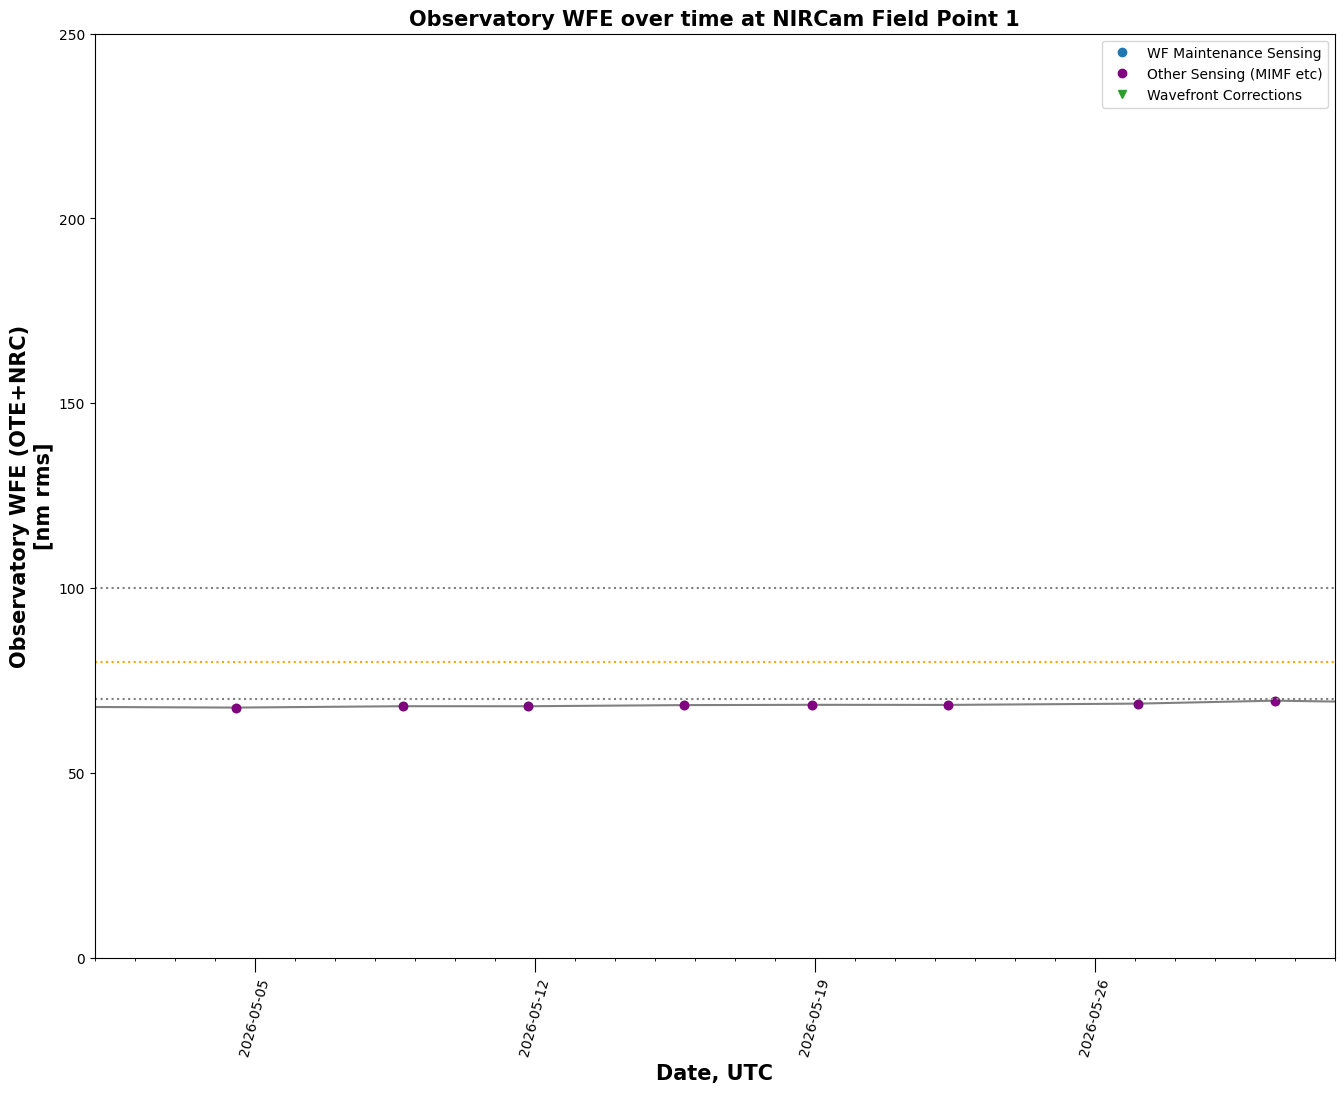

In [19]:
opdtable = stpsf.mast_wss.retrieve_mast_opd_table()
opdtable = stpsf.mast_wss.deduplicate_opd_table(opdtable)
stpsf.mast_wss.download_all_opds(opdtable)
stpsf.trending.wavefront_time_series_plot(opdtable,label_visits=False,start_date=astropy.time.Time('2026-05-01'),end_date=astropy.time.Time('2026-06-01'))
#stpsf.trending.wfe_histogram_plot(opdtable, thresh=80, mark_corrections='arrows')
#start_time =  astropy.time.Time('2022-07-16')
#stpsf.trending.delta_wfe_around_time(datetime=start_time)

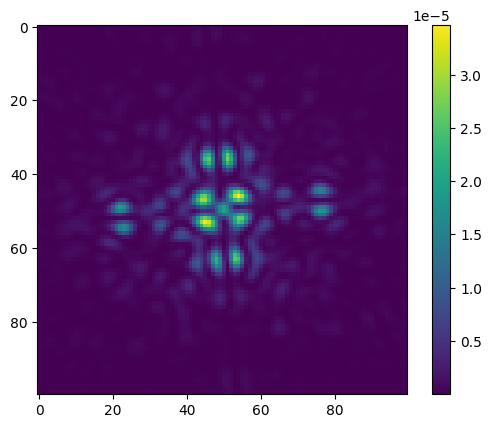

In [9]:
plt.imshow(obs)
plt.colorbar()

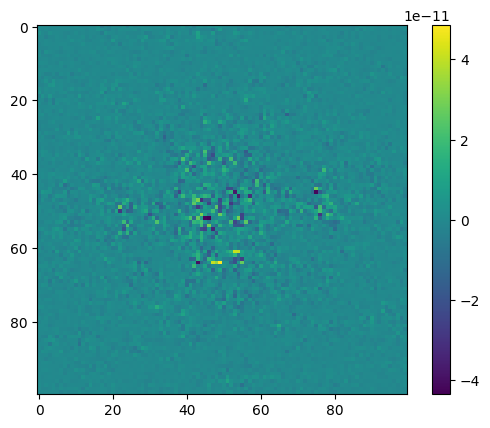

In [24]:
plt.imshow(obs_noise - flux_Jy)
plt.colorbar()
plt.show()

In [25]:
np.sum(obs)

np.float64(0.009946191272078402)